# Optique de Fourier

On considère une onde monochromatique de pulsation $\omega$ se propageant verticalement (axe $z$). On pose $k = \omega/c = 2\pi/\lambda$ où $c$ est la vitesse de la lumière.
L'approximation paraxiale consiste à supposer que l'angle que forme l'onde avec l'axe de propagation est très faible. Dans ce cas, on peut écrire l'amplitude de l'onde sous la forme $U(x, y, z, t) = e^{i(\omega t - k z)} A(x, y, z)$ où $A$ vérifie l'équation :

$$
2 i k \partial_z A = \partial_x^2 A + \partial_y^2 A
$$

Dans la suite, nous ne considérerons que le cas unidimensionnel (on enlève $y$), soit l'équation suivante :

$$
2 i k \partial_z A = \partial_x^2 A
$$

où maintenant $A$ est une fonction de $x$ et $z$.

On peut réécrire cette équation sous la forme : 

$$
\partial_z A = -\frac{i}{2  k} \partial_x^2 A
$$

L'objectif de cet exercice sera de calculer l'amplitude $A$ en fonction de $z$. Dans un premier temps, nous allons considérer une solution analytique (un faisceau gaussien) avant de résoudre le problème numériquement.
On prendra $\lambda = 1$ µm.

## Faisceau gaussien

On considère un faisceau gaussien de waist (taille) $w_0$ en $z=0$. L'amplitude $A(x, 0)$ est donnée par :

$$
A(x, 0) = E_0 e^{-x^2/w_0^2}
$$

On prendra $w_0 = 0.1$ mm et $E_0 = 1$. L'intensité lumineuse est donnée (à une constante près) par $I(x, z) = |A(x, z)|^2$.

1. Tracer l'intensité $I(x, 0)$ en fonction de $x$.

In [1]:
import numpy as np
from matplotlib.pyplot import figure
from scipy.integrate import quad
from numpy.fft import fft, fftfreq, fftshift, ifft

Text(0, 0.5, 'I')

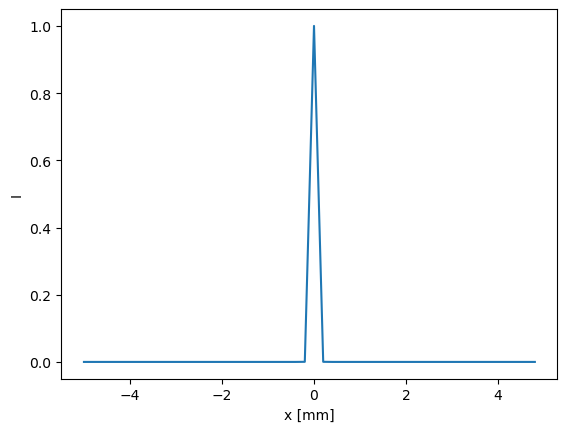

In [2]:
import numpy as np
from matplotlib.pyplot import figure

def gauss(x, w_0):
    return np.exp(-x**2/w_0**2)

L = 10E-3
w_0 = .1E-3


fig = figure()
ax = fig.subplots(1, 1)

Tx = np.linspace(-L/2, L/2, endpoint=False)

ax.plot(Tx*1E3, gauss(Tx, w_0)**2)
ax.set_xlabel('x [mm]')
ax.set_ylabel('I')

2. Calculer numériquement la puissance totale qui est donnée par : $P = \int I(x, 0) \, dx$.

In [3]:
from scipy.integrate import quad

quad(gauss, -1E-1, 1E-1, (w_0,))[0]

0.0001772453850905516

## Propagation par transformée de Fourier

On échantillonne la fonction $A(x, 0)$ sur un intervalle $[-L/2, L/2[$ avec $N$ points. La transformée de Fourier numérique de ce tableau va correspondre à la distribution en vecteur d'onde $k_x$ : le pas sera donné par $2\pi/L$ et le vecteur d'onde maximal sera compris dans $[-\pi/\delta, \pi/\delta]$ où $\delta = L/N$.

3. Tracer la transformée de Fourier de l'amplitude $A(x, 0)$. Vérifier que l'on obtient une courbe proportionnelle à $e^{-k_x^2 w_0^2/4}$. On ne s'occupera pas de l'amplitude.

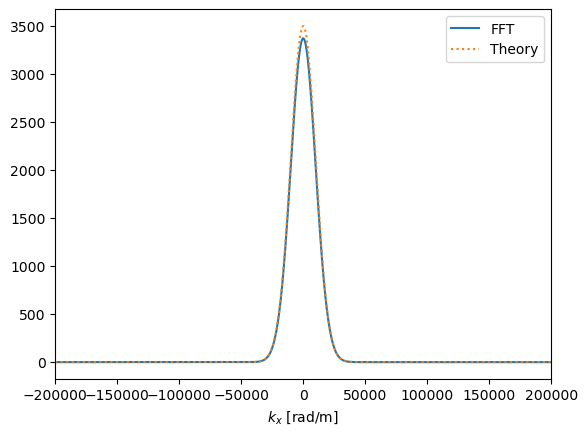

In [8]:
from numpy.fft import fft, fftfreq, fftshift, ifft

N = 2**15
L = 100E-3
w_0 = .1E-3
Tx = np.linspace(-L/2, L/2, N, endpoint=False)

delta = L/N

a_0 =  gauss(Tx, w_0)

a_0_tilde = fft(a_0)
Tk_x = 2*np.pi*fftfreq(N, d=delta)

fig = figure()
ax = fig.subplots(1, 1)

ax.plot(fftshift(Tk_x), np.abs(fftshift(a_0_tilde))**2, label='FFT')
ax.set_xlabel('$k_x$ [rad/m]')

Tk_xb = fftshift(Tk_x)
ax.plot(Tk_xb, 3500*np.exp(-Tk_xb**2*w_0**2/2), ':', label='Theory')
ax.set_xlim(-0.2E6, 0.2E6)
ax.legend()


L'équation paraxiale nous dit que, après une propagation sur une distance $D$, la composante ayant un vecteur d'onde $k_x$ subira un déphasage donné par $\frac{k_x^2 D}{2k}$.

Donc, pour calculer $A(x, D)$, on calcule d'abord $\tilde{A}(k_x, 0)$, puis $\tilde{A}(k_x, D) = \tilde{A}(k_x, 0) e^{i \frac{k_x^2 D}{2k}}$, et enfin $A(x, D)$.

4. Écrire une fonction qui, partant d'un tableau $a_i = A(x_i, 0)$, calcule $A(x_i, D)$.

In [10]:
lamb = 1E-6
k = 2*np.pi/lamb

def propagation(a_0, D, L, N):
    delta = L/N
    a_0_tilde = fft(a_0)
    Tk_x = 2*np.pi*fftfreq(N, d=delta)
    a_D_tilde = a_0_tilde*np.exp(1J*Tk_x**2*D/k/2)
    return ifft(a_D_tilde)
    
N = 2**15
L = 100E-3
w_0 = .1E-3
D = .1
Tx = np.linspace(-L/2, L/2, N, endpoint=False)
    
a_D = propagation(gauss(Tx, w_0), D, L, N)    

5. Calculer $A(x, D)$ pour $D = 10$ cm et tracer l'intensité. Comparer graphiquement avec l'intensité donnée par la formule analytique suivante : $\frac{w_0}{w(z)} e^{-2x^2/w(z)^2}$ où $w(z) = w_0 \left(1 + \frac{z^2}{z_R^2}\right)$ avec $z_R = \pi w_0^2/\lambda$. On prendra $L = 10$ cm et $N = 2^{15}$.

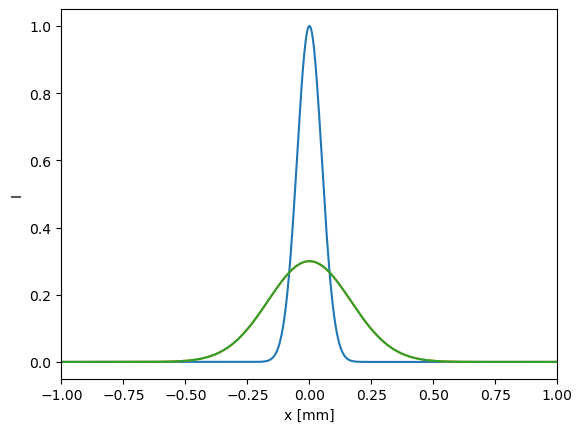

In [13]:
fig = figure()
ax = fig.subplots(1, 1)

ax.plot(Tx*1E3, gauss(Tx, w_0)**2)
ax.plot(Tx*1E3, np.abs(a_D)**2)
ax.set_xlabel('x [mm]')
ax.set_ylabel('I')
ax.set_xlim(-1, 1)

z_R = np.pi*w_0**2/lamb
ax.plot(Tx*1E3, gauss(Tx, w_0*np.sqrt(1+(D/z_R)**2))**2*.3)

## Fentes de Young

6. On considère deux fentes de 100 µm séparées de 500 µm éclairées par une onde plane. Tracer, pour $D = 30$ cm, la figure d'interférence.


7. On considère le tableau 2D $I(x, z)$ pour $z \in [0, D]$. Calculer ce tableau et le tracer avec la fonction `imshow`. **Attention** : on effectuera toujours le calcul avec $N = 2^{15}$ points, mais on pourra sous-échantillonner le tableau selon x. On utilisera l'option ``extent`` de ``imshow`` pour afficher correctement les axes. L'image ressemble à ceci :

```{image} fentes_young.jpg
:alt: Fentes de Young
:width: 50%
:align: center
```


In [14]:
N = 2**15
L = 100E-3
w_0 = .1E-3
d = .5E-3
h = 100E-6
D = .1
Tx = np.linspace(-L/2, L/2, N, endpoint=False)

a_0 = np.zeros_like(Tx)

a_0[np.abs(np.abs(Tx) - d/2)<h/2] = 1

D = 0.3
a_D = propagation(a_0, D, L, N)   

(-5.0, 5.0)

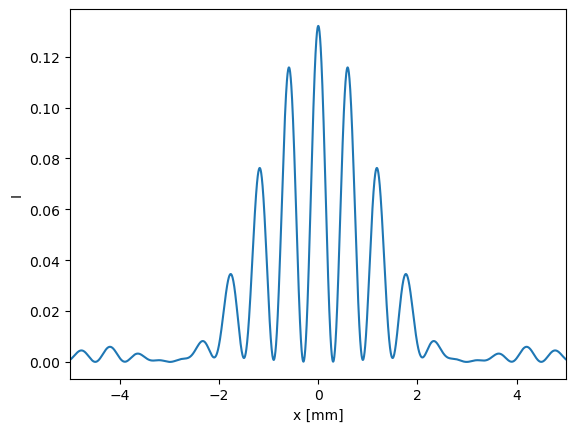

In [15]:
fig = figure()
ax = fig.subplots(1, 1)

#ax.plot(Tx*1E3, a_0**2)
ax.plot(Tx*1E3, np.abs(a_D)**2)
ax.set_xlabel('x [mm]')
ax.set_ylabel('I')
ax.set_xlim(-5, 5)
#ax.plot(Tx*1E3, gauss(Tx, w_0*np.sqrt(1+(D/z_R)**2))**2*.3)

In [16]:
TD = np.linspace(0, D, 512)

mask = np.abs(Tx)<5E-3

out = []
for D in TD:
    a_D = propagation(a_0, D, L, N)  
    out.append(a_D[mask][::8])
out = np.array(out)

out.shape

(512, 410)

Text(0, 0.5, 'x [m]')

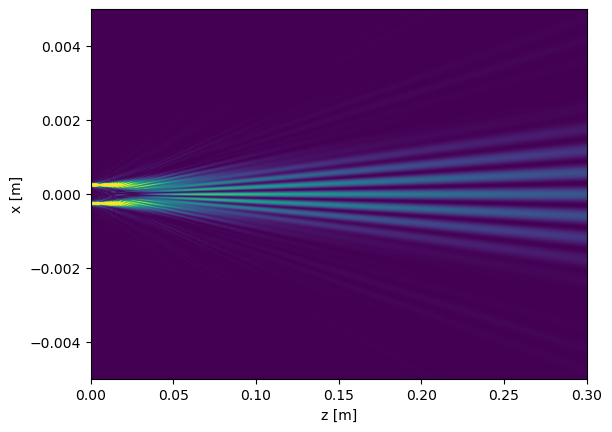

In [17]:
fig = figure()
ax = fig.subplots(1, 1)

ax.imshow(np.abs(out.T)**2, vmax=.5, extent=[0, D, -5E-3, 5E-3], aspect='auto')
ax.set_xlabel('z [m]')
ax.set_ylabel('x [m]')

